# Exercise 4 — E-Commerce Text & Quantitative Analytics
**Trainee:** Akhilesh Jaiswal | **Program:** GOT-A

## Objective
Use the **Flipkart Product Customer Reviews Dataset (Kaggle)**. Clean rating and price fields; group records by product name; calculate mean rating and mean price in a DataFrame named `items`; create a Word Cloud from `Summary`.

**Concepts:** `groupby` groups rows by a common product; `mean` calculates the average; a Word Cloud displays frequent words in larger type.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud, STOPWORDS

PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

KAGGLE_CSV = DATA_DIR / "flipkart_product_customer_reviews.csv"
PRACTICE_CSV = DATA_DIR / "sample_reviews_for_practice.csv"

if KAGGLE_CSV.exists():
    data_path = KAGGLE_CSV
    print("Using Kaggle dataset:", data_path.name)
else:
    data_path = PRACTICE_CSV
    print("WARNING: Kaggle CSV not found; using synthetic practice data.")
    print("Replace this with the required Kaggle dataset for final submission.")

df = pd.read_csv(data_path)
print("Dataset shape:", df.shape)
print("Columns:", list(df.columns))
display(df.head())

Using Kaggle dataset: flipkart_product_customer_reviews.csv
Dataset shape: (205052, 6)
Columns: ['product_name', 'product_price', 'Rate', 'Review', 'Summary', 'Sentiment']


,product_name,product_price,Rate,Review,Summary,Sentiment
0,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,5,super!,great cooler excellent air flow and for this p...,positive
1,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,5,awesome,best budget 2 fit cooler nice cooling,positive
2,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,3,fair,the quality is good but the power of air is de...,positive
3,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,1,useless product,very bad product its a only a fan,negative
4,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999,3,fair,ok ok product,neutral


## Task 4.1 — Clean rating and price
Different Kaggle dataset copies may use slightly different column headers. The code checks common names and tells you if a field needs manual mapping.

In [2]:
def find_column(columns, candidates):
    normalized = {str(c).strip().lower().replace(" ", "_"): c for c in columns}
    for candidate in candidates:
        key = candidate.lower().replace(" ", "_")
        if key in normalized:
            return normalized[key]
    return None

product_col = find_column(df.columns, ["product_name", "product", "product_title"])
rating_col = find_column(df.columns, ["rating", "ratings", "rate"])
price_col = find_column(df.columns, ["price", "product_price", "discounted_price", "selling_price"])
summary_col = find_column(df.columns, ["summary", "review_summary", "review", "review_text"])

print("Detected columns:", product_col, rating_col, price_col, summary_col)
if None in [product_col, rating_col, price_col, summary_col]:
    raise ValueError("A required column was not detected. Inspect df.columns and edit the candidate lists.")

work = df[[product_col, rating_col, price_col, summary_col]].copy()
work.columns = ["product_name", "rating", "price", "Summary"]

work["rating"] = pd.to_numeric(
    work["rating"].astype(str).str.extract(r"([0-9]+(?:\.[0-9]+)?)")[0],
    errors="coerce"
)
work["price"] = pd.to_numeric(
    work["price"].astype(str).str.replace(",", "", regex=False)
        .str.replace(r"[^0-9.]", "", regex=True),
    errors="coerce"
)
work["product_name"] = work["product_name"].astype(str).str.strip()
work["Summary"] = work["Summary"].fillna("").astype(str).str.strip()
work = work.replace({"product_name": {"": pd.NA, "nan": pd.NA}})
work = work.dropna(subset=["product_name", "rating", "price"])
work = work[work["Summary"] != ""]
print("Cleaned rows:", len(work))
display(work.head())

Detected columns: product_name Rate product_price Summary
Cleaned rows: 205041


,product_name,rating,price,Summary
0,Candes 12 L Room/Personal Air Cooler??????(Whi...,5.0,3999,great cooler excellent air flow and for this p...
1,Candes 12 L Room/Personal Air Cooler??????(Whi...,5.0,3999,best budget 2 fit cooler nice cooling
2,Candes 12 L Room/Personal Air Cooler??????(Whi...,3.0,3999,the quality is good but the power of air is de...
3,Candes 12 L Room/Personal Air Cooler??????(Whi...,1.0,3999,very bad product its a only a fan
4,Candes 12 L Room/Personal Air Cooler??????(Whi...,3.0,3999,ok ok product


## Task 4.2 — Calculate mean rating and mean price
The grouped output is stored in a DataFrame named exactly `items`, as required.

In [3]:
items = (
    work.groupby("product_name", as_index=False)
        .agg(mean_rating=("rating", "mean"), mean_price=("price", "mean"))
        .sort_values("product_name")
)
display(items.head(20))
items.to_csv(OUTPUT_DIR / "Exercise4_Product_Summary.csv", index=False)
print("Saved product summary CSV.")

,product_name,mean_rating,mean_price
0,1170BLBR Unique New Day Date Analog Watch F...,3.986667,299.0
1,288SDTL TIMEWEAR Silver Pink Dial Stainless St...,4.406915,339.0
2,38024PP25 Minimalists Analog Watch For Men,4.888889,850.0
3,3D METRO SUPER STORE JUICERGduumy 1 Juicer1 Ha...,3.670000,417.0
4,3D METRO SUPER STORE METROMIXER Pro 0 Juicer 1...,4.750000,199.0
5,77085PP03 Volt Analog Watch For Men,4.711111,699.0
6,7SEVEN Airtel DTH Remote Airtel Xstream Remote...,4.687500,219.0
7,"ADONYX Combo of Knee,Palm, Elbow & Ankle Support",3.803571,199.0
8,ADZOY Metal Lazy Stand Bracket for Neck Rest o...,3.516129,284.0
9,AGAMI Green 2 Layer Lucky Bamboo plant with Bi...,4.455000,279.0


Saved product summary CSV.


## Task 4.3 — Word Cloud from the Summary column
The Word Cloud visualizes frequent customer feedback terms.

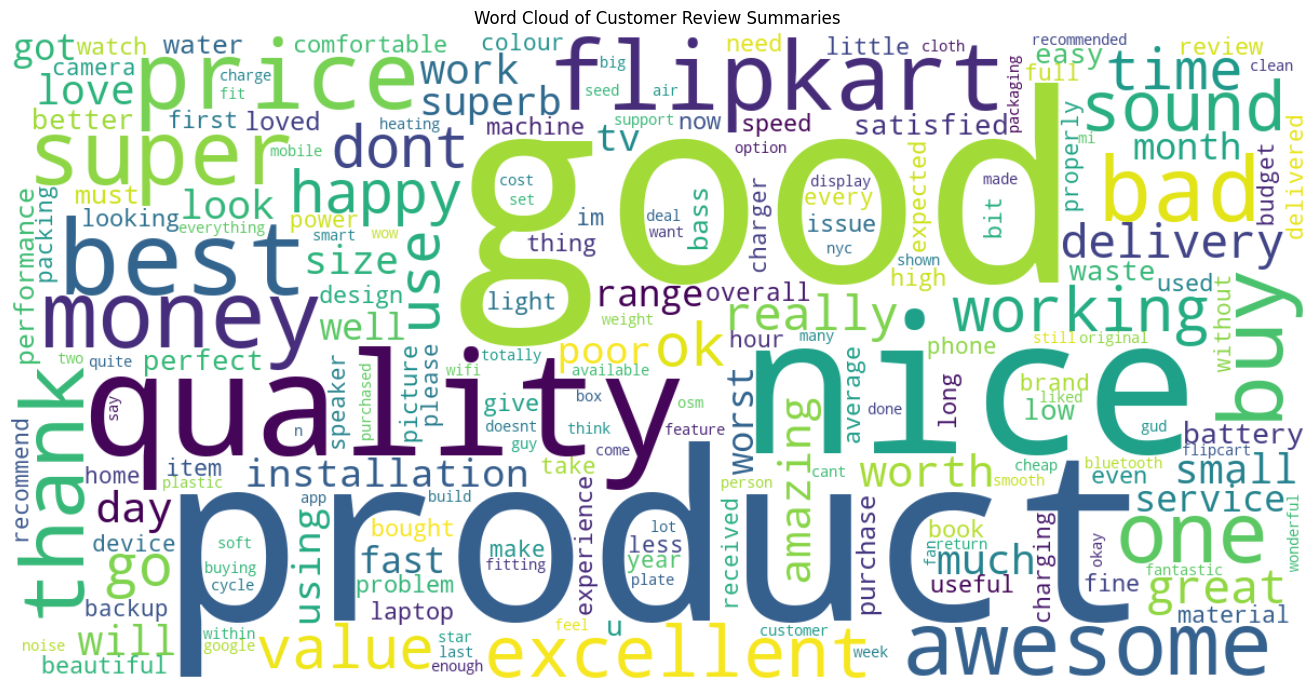

In [5]:
review_text = " ".join(work["Summary"].astype(str).tolist())
if not review_text.strip():
    raise ValueError("No review text is available in Summary.")

wordcloud = WordCloud(
    width=1200, height=600, background_color="white",
    stopwords=set(STOPWORDS), collocations=False
).generate(review_text)

plt.figure(figsize=(14,7))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud of Customer Review Summaries")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "Exercise4_WordCloud.png", dpi=150)
plt.show()

## Result
Cleaned numeric rating and price fields; grouped by product name; calculated average rating and price in `items`; and generated a Word Cloud from `Summary`.
